In [3]:
import pandas as pd
#Path to CSV exported from GEE
file_path = r'C:\Users\AFahrezi\Documents\GitHub\Improve_pixel_based_lc_classification\input_data\AFCLIM_Feature_extraction_S2_2025_update.csv'
df = pd.read_csv(file_path)
# Inspect dataset shape
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")
# Define target label column name
target_col = 'new_id'
# Drop non-feature GEE metadata and target column to isolate X
X = df.drop(columns=['.geo', 'system:index', target_col], errors='ignore')
y = df[target_col]
print(f"Features to evaluate ({X.shape[1]} total):")
print(list(X.columns))

Total Rows: 3891, Total Columns: 58
Features to evaluate (55 total):
['B11_dry', 'B11_wet', 'B12_dry', 'B12_wet', 'B2_dry', 'B2_wet', 'B3_dry', 'B3_wet', 'B4_dry', 'B4_wet', 'B8_dry', 'B8_wet', 'BLFEI_delta', 'BLFEI_dry', 'BLFEI_wet', 'DBSI_delta', 'DBSI_dry', 'DBSI_wet', 'GBNDVI_dry', 'GBNDVI_wet', 'MBI_delta', 'MBI_dry', 'MBI_wet', 'MNDWI_delta', 'MNDWI_dry', 'MNDWI_wet', 'MSAVI_delta', 'MSAVI_dry', 'MSAVI_wet', 'NDMI_delta', 'NDMI_dry', 'NDMI_wet', 'NDVI_dry', 'NDVI_wet', 'ScanSAR_HH_dB', 'ScanSAR_HV_dB', 'TWI', 'VH_dry', 'VH_wet', 'VV_dry', 'VV_wet', 'aspect', 'elevation', 'landform', 'nir_amp', 'nir_asm', 'nir_contrast', 'nir_ent', 'nir_idm', 'nir_phase', 'red_amp', 'red_phase', 'slope', 'swir1_amp', 'swir1_phase']


In [22]:
#Initialize base Random Forest estimator
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1)

# Set up RFECV using Stratified 5-Fold Cross-Validation
rfecv = RFECV(estimator=rf,step=1,                          
    cv=StratifiedKFold(7, shuffle=True, random_state=42),          
    scoring='f1_macro',              
    min_features_to_select=15,       
    n_jobs=-1
)

# Fit RFECV on training samples
print("Running RFECV feature selection...")
rfecv.fit(X, y)

print(f"\nOptimal number of features selected: {rfecv.n_features_}")

Running RFECV feature selection...

Optimal number of features selected: 50


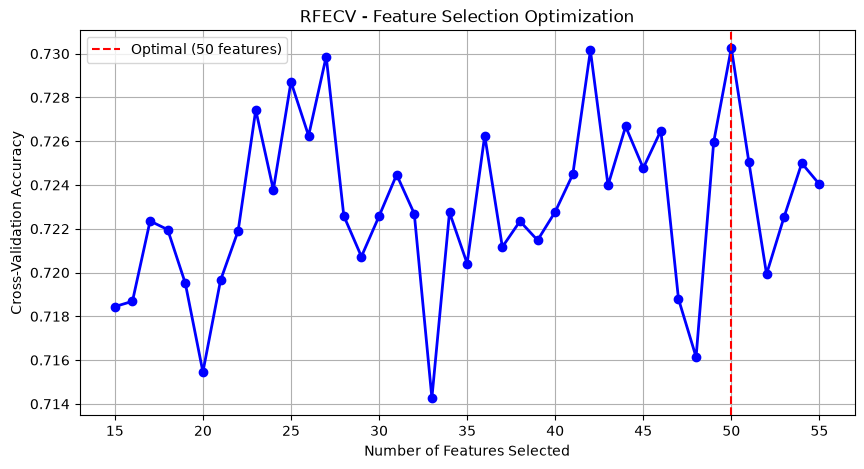

In [23]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.xlabel("Number of Features Selected")
plt.ylabel("Cross-Validation Accuracy")
plt.title("RFECV - Feature Selection Optimization")

# Extract CV scores across feature subsets
scores = rfecv.cv_results_['mean_test_score']
n_features_range = range(rfecv.min_features_to_select, len(scores) + rfecv.min_features_to_select)

plt.plot(n_features_range, scores, marker='o', color='b', linewidth=2)
plt.axvline(x=rfecv.n_features_, color='r', linestyle='--', label=f'Optimal ({rfecv.n_features_} features)')

plt.legend()
plt.grid(True)
plt.show()

In [24]:
# Extract selected feature names
selected_bands = list(X.columns[rfecv.support_])
# Convert to Google Earth Engine JS array format
gee_js_code = "var selectedBands = " + str(selected_bands).replace("'", '"') + ";"
print(gee_js_code)

var selectedBands = ["B11_dry", "B11_wet", "B12_dry", "B12_wet", "B2_dry", "B2_wet", "B3_dry", "B3_wet", "B4_dry", "B4_wet", "B8_dry", "B8_wet", "BLFEI_delta", "BLFEI_dry", "BLFEI_wet", "DBSI_delta", "DBSI_dry", "DBSI_wet", "GBNDVI_dry", "GBNDVI_wet", "MBI_delta", "MBI_dry", "MBI_wet", "MNDWI_delta", "MNDWI_dry", "MNDWI_wet", "MSAVI_delta", "MSAVI_dry", "MSAVI_wet", "NDMI_delta", "NDMI_dry", "NDMI_wet", "NDVI_dry", "NDVI_wet", "ScanSAR_HH_dB", "ScanSAR_HV_dB", "TWI", "VH_dry", "VH_wet", "VV_dry", "VV_wet", "elevation", "nir_amp", "nir_contrast", "nir_phase", "red_amp", "red_phase", "slope", "swir1_amp", "swir1_phase"];


In [ ]:
var selectedBands = ["B11_dry", "B11_wet", "B12_dry", "B12_wet", "B2_dry", "B2_wet", "B3_dry", 
                     "B3_wet", "B4_dry", "B4_wet", "B8_dry", "B8_wet", "BLFEI_delta", "BLFEI_dry", 
                     "BLFEI_wet", "DBSI_delta", "DBSI_dry", "DBSI_wet", 
                     "GBNDVI_dry", "GBNDVI_wet", "MBI_delta", "MBI_dry", "MBI_wet", "MNDWI_delta",
                    "MNDWI_dry", "MNDWI_wet", "MSAVI_delta", "MSAVI_dry", "MSAVI_wet", "NDMI_delta", "NDMI_dry", "NDMI_wet", "NDVI_dry", "NDVI_wet", 
                     "ScanSAR_HH_dB", "ScanSAR_HV_dB", "TWI", "VH_dry", "VH_wet", "VV_dry", "VV_wet", 
                     "elevation", "nir_amp", "nir_contrast", "nir_phase", "red_amp", "red_phase", "slope", "swir1_amp", "swir1_phase"]

In [ ]:
var selectedBands = ["B11_dry", "B11_wet", "B12_dry", "B12_wet", "B2_dry", "B2_wet", "B3_dry", "B3_wet", "B4_dry", "B4_wet", "B8_dry", "B8_wet", "BLFEI_delta", 
                     "BLFEI_dry", "BLFEI_wet", "DBSI_delta", "DBSI_dry", "DBSI_wet", "GBNDVI_dry", "GBNDVI_wet", "MBI_delta", "MBI_dry", "MBI_wet", "MNDWI_delta", 
                     "MNDWI_dry", "MNDWI_wet", "MSAVI_delta", "MSAVI_dry", "MSAVI_wet", 
                     "NDMI_delta", "NDMI_dry", "NDMI_wet", "NDVI_dry", "NDVI_wet", 
                     "ScanSAR_HH_dB", "ScanSAR_HV_dB", "TWI", "VH_dry", "VH_wet", "VV_dry", "VV_wet", "elevation", "nir_amp",
                       "nir_contrast", "nir_phase", "red_amp", "red_phase", "slope", "swir1_amp", "swir1_phase"]